# PINGS GS → colored point cloud from rendered RGB-D

**Purpose:** export a point cloud from the GS representation that you inspected successfully. The existing 12 mm mesh and the previous SDF point sampler are not used. The model and all poses are frozen. No SLAM, training, SDF querying, meshing, or ICP is performed.

The notebook uses the native PINGS renderer's `render`, `surf_depth`, and `rend_alpha`, back-projects valid pixels, checks depth consistency across nearby views, and keeps one source view per spatial surface patch. Neither XYZ nor RGB are averaged across views.

**Quality boundary:** good-looking RGB does not prove accurate depth. Inspect the single-view point cloud from several angles before combining views. A denser render samples the trained GS representation more finely; it cannot restore image detail absent from training or establish 0.1 mm accuracy. The 1 mm voxel below controls deduplication only.

All comments, instructions, and mathematical notes are in English. The real checkpoint and CUDA renderer were not available in the authoring environment. CPU geometry, camera transforms, consistency filtering, coherent view selection, resumable export, and PLY output are tested synthetically; the first model render is the local integration check.


## 1. Configuration

Run in the existing `pings` kernel. Start with frame 454 and the small preview interval. `RENDER_SCALE=2` renders twice the native width and height with scaled intrinsics; it does not resize a previously rendered image. It costs approximately four times as many pixels. Use scale 1 first if VRAM is limited.

Preview/full runs reuse compatible cached RGB-D views and point files. Changing render or filter settings automatically selects a different cache directory. Export uses one camera at a time so source-view identity is unambiguous.


In [8]:
from pathlib import Path

PINGS_REPO = Path('/home/ntd/my_ws/PINGS')
EXPERIMENT = Path('/home/ntd/data/fast_livo2/pings_results/gs_no_deskew/hku_landmark_stable_fastlivo2__2026-10-22_13-07-25')
DEVICE = 'cuda:0'
DATA_ROOT_OVERRIDE = None
POSE_CONVENTION = 'pings_export'
EXPORT_ROOT = EXPERIMENT / 'exports_gs_rgbd_v1'

CAMERA = 'cam'
QA_FRAME = 454
RENDER_SCALE = 2

PREVIEW_BEGIN = 440
PREVIEW_END = 471
PREVIEW_STEP = 5
FULL_BEGIN = 0
FULL_END = -1
FULL_STEP = 3

OPTIONS = dict(
    alpha_min=0.90,
    min_depth_m=0.5,
    max_depth_m=30.0,
    pixel_stride=1,
    depth_edge_abs_m=0.03,
    depth_edge_rel=0.005,
    consistency_abs_m=0.015,
    consistency_rel=0.003,
    min_other_views=1,
    neighbor_views=3,
    min_baseline_m=0.02,
    min_incidence=0.15,
    output_voxel_m=0.001,
    color_patch_m=0.25,
    bucket_count=32,
    roi=None,
)
# Example ROI in PINGS world coordinates: [[xmin, ymin, zmin], [xmax, ymax, zmax]].

OPEN_SINGLE_VIEW = False
OPEN_PREVIEW = True
RUN_FULL_EXPORT = True
print('Export directory:', EXPORT_ROOT)


Export directory: /home/ntd/data/fast_livo2/pings_results/gs_no_deskew/hku_landmark_stable_fastlivo2__2026-10-22_13-07-25/exports_gs_rgbd_v1


## 2. Environment and embedded exporter

The PINGS checkout and its existing compiled rasterizer must already work, as in `inspect_pings.py --show-gs`. This notebook does not install or rebuild CUDA dependencies. No neural-map files are modified.


In [9]:
import importlib.util

required = ['numpy', 'scipy', 'torch', 'yaml', 'open3d', 'matplotlib', 'tqdm']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(f'Select the working pings kernel. Missing modules: {missing}')


In [10]:
"""Frozen PINGS GS RGB-D export. No SDF queries, meshing or pose fitting."""
from pathlib import Path
from dataclasses import dataclass, asdict
import copy
import hashlib
import inspect
import json
import os
import sys
import time
import numpy as np
from scipy.ndimage import maximum_filter, minimum_filter

VERSION = 'pings_gs_rgbd_v1'
POINT_DTYPE = np.dtype([
    ('x','<f4'),('y','<f4'),('z','<f4'),
    ('nx','<f4'),('ny','<f4'),('nz','<f4'),
    ('red','u1'),('green','u1'),('blue','u1'),
    ('alpha','<f4'),('score','<f4'),('source_frame','<i4'),
    ('source_u','<i4'),('source_v','<i4'),('support','<u2'),('bucket','u1')])
PATCH_DTYPE = np.dtype([(k,'<i8') for k in ('x','y','z','a','b','c')])


def plain(value):
    if isinstance(value,np.ndarray): return value.tolist()
    if isinstance(value,np.generic): return value.item()
    if isinstance(value,Path): return str(value)
    if isinstance(value,dict): return {str(k):plain(v) for k,v in value.items()}
    if isinstance(value,(tuple,list)): return [plain(v) for v in value]
    return value


def digest(value):
    return hashlib.sha256(json.dumps(plain(value),sort_keys=True,allow_nan=False).encode()).hexdigest()


def atomic_json(path,value):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(path.suffix+'.tmp')
    temporary.write_text(json.dumps(plain(value),indent=2,allow_nan=False))
    temporary.replace(path)


def atomic_npy(path,rows):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(path.suffix+'.tmp')
    with temporary.open('wb') as stream: np.save(stream,rows,allow_pickle=False)
    temporary.replace(path)


def xyz(rows):
    return np.column_stack([rows[k] for k in ('x','y','z')])


def normals(rows):
    return np.column_stack([rows[k] for k in ('nx','ny','nz')])


def validate_pose(T):
    T=np.asarray(T,np.float64)
    if T.shape!=(4,4) or not np.isfinite(T).all() or not np.allclose(T[3],[0,0,0,1]):
        raise ValueError('Expected a finite homogeneous 4x4 transform.')
    if not np.allclose(T[:3,:3].T@T[:3,:3],np.eye(3),atol=1e-3) or np.linalg.det(T[:3,:3])<=0:
        raise ValueError('Invalid transform rotation.')
    return T


def read_poses(path):
    data=np.loadtxt(path,ndmin=2)
    if data.shape[1] not in (12,16): raise ValueError('Expected KITTI 12/16-column poses.')
    result=np.tile(np.eye(4),(len(data),1,1))
    if data.shape[1]==12: result[:,:3,:]=data.reshape(-1,3,4)
    else: result[:]=data.reshape(-1,4,4)
    for T in result: validate_pose(T)
    return result


class PingsGSRenderer:
    """Use the checkpoint GS decoders and native renderer in frozen inference."""
    def __init__(self,repo,experiment,device='cuda:0',data_root=None,pose_convention='pings_export'):
        import torch
        import yaml
        self.torch=torch
        self.repo=Path(repo).expanduser().resolve()
        self.experiment=Path(experiment).expanduser().resolve()
        self.checkpoint=self.experiment/'model/pin_map.pth'
        config_path=self.experiment/'meta/config_all.yaml'
        for path in [self.repo/'model/neural_gaussians.py',self.checkpoint,config_path]:
            if not path.is_file(): raise FileNotFoundError(path)
        if not device.startswith('cuda') or not torch.cuda.is_available():
            raise RuntimeError('Select the existing CUDA-enabled pings kernel.')
        sys.path.insert(0,str(self.repo)); os.chdir(self.repo)
        from model.decoder import Decoder
        from dataset.slam_dataset import SLAMDataset
        from gaussian_splatting.gaussian_renderer import render
        from gaussian_splatting.utils.cameras import CamImage
        self.native_render=render; self.CamImage=CamImage
        required={'down_rate','gs_type','displacement_range_ratio','max_scale_ratio','unit_scale_ratio'}
        if not required<=inspect.signature(render).parameters.keys():
            raise RuntimeError('The local PINGS renderer API differs from the checked implementation.')
        # The checkpoint is the user's existing PINGS model; its custom class is required.
        saved=torch.load(str(self.checkpoint),map_location=device,weights_only=False)
        self.map=saved['neural_points']
        cfg=copy.deepcopy(self.map.config)
        full=yaml.safe_load(config_path.read_text())
        for key,value in full.items(): setattr(cfg,key,value)
        cfg.device=device; cfg.setup_dtype(); cfg.dtype=self.map.neural_points.dtype
        cfg.gs_on=True; cfg.use_dataloader=True; cfg.monodepth_on=False
        cfg.run_path=str(self.experiment); cfg.silence=True
        if data_root is not None: cfg.pc_path=str(Path(data_root).expanduser())
        if not Path(cfg.pc_path).exists(): raise FileNotFoundError(cfg.pc_path)
        self.dataset=SLAMDataset(cfg)
        self.config=self.dataset.config; self.device=device
        cfg=self.config
        self.map.config=cfg; self.map.device=device; self.map.temporal_local_map_on=False
        self.map.eval()
        for parameter in self.map.parameters(): parameter.requires_grad_(False)
        architecture={
            'gauss_xyz':(cfg.feature_dim,3,0),
            'gauss_rot':(cfg.feature_dim,4,0),
            'gauss_scale':(cfg.feature_dim,3,0),
            'gauss_alpha':(cfg.feature_dim,1,1 if cfg.dist_concat_on else 0),
            'gauss_color':(cfg.color_feature_dim,3,3 if cfg.view_concat_on else 0)}
        self.decoders={}
        for key,(feature_dim,out_dim,pos_dim) in architecture.items():
            if saved.get(key) is None: raise RuntimeError(f'Missing GS decoder: {key}')
            decoder=Decoder(cfg,feature_dim,cfg.gs_mlp_hidden_dim,cfg.gs_mlp_level,
                            out_dim,cfg.spawn_n_gaussian,pos_dim)
            decoder.load_state_dict(saved[key],strict=True); decoder.eval()
            for parameter in decoder.parameters(): parameter.requires_grad_(False)
            self.decoders[key]=decoder
        # Global tensors preserve the exact anchor positions and feature sentinel row.
        m=self.map; count=len(m.neural_points)
        self.data={'position':m.neural_points,'orientation':m.point_orientations,
                   'geo_feature':m.geo_features,'color_feature':m.color_features,
                   'resolution':m.resolution}
        for key,attribute in [('color','point_colors'),('valid_mask','valid_gs_mask'),
                              ('free_mask','free_gs_mask'),('stability','point_certainties')]:
            value=getattr(m,attribute,None)
            if value is not None: self.data[key]=value
        if len(m.geo_features)!=count+1 or len(m.color_features)!=count+1:
            raise RuntimeError('Expected one dummy/sentinel row in each feature tensor.')
        for key in ('orientation','color','valid_mask','free_mask','stability'):
            if key in self.data and len(self.data[key])!=count:
                raise RuntimeError(f'Unexpected global map tensor length: {key}')
        self.background=torch.as_tensor(cfg.bg_color,dtype=cfg.dtype,device=device)
        self.pose_path=self.experiment/'slam_poses_kitti.txt'
        self.poses=read_poses(self.pose_path)
        self.Tr=validate_pose(np.asarray(self.dataset.calib['Tr']))
        if pose_convention=='pings_export':
            self.poses=np.linalg.inv(self.Tr)[None]@self.poses@self.Tr[None]
        elif pose_convention!='internal_lidar': raise ValueError('Unknown pose convention.')
        self.camera_names=list(self.dataset.K_mats or {})
        if not self.camera_names: raise RuntimeError('The loader supplies no camera calibration.')
        self.frame_count=len(self.poses)
        self.identity={'version':VERSION,'checkpoint':str(self.checkpoint),
                       'checkpoint_size':self.checkpoint.stat().st_size,
                       'checkpoint_mtime_ns':self.checkpoint.stat().st_mtime_ns,
                       'config_sha256':hashlib.sha256(config_path.read_bytes()).hexdigest(),
                       'poses_sha256':hashlib.sha256(self.poses.tobytes()).hexdigest(),
                       'renderer_sha256':hashlib.sha256(inspect.getsource(render).encode()).hexdigest(),
                       'pose_convention':pose_convention,'Tr':self.Tr,'data_root':cfg.pc_path}
        del saved
        print('Frozen GS model:',self.checkpoint)
        print('GS type:',cfg.gs_type,'| anchors:',f'{count:,}','| poses:',self.frame_count)
        print('Export calibration Tr:\n',self.Tr)
        print('No SDF decoder is loaded or queried. No mesh is used.')

    def render(self,frame_id,camera,scale=1):
        if not 0<=frame_id<self.frame_count: raise IndexError(frame_id)
        if camera not in self.camera_names: raise KeyError(camera)
        if scale not in (1,2,4): raise ValueError('Render scale must be 1, 2 or 4.')
        torch=self.torch; cfg=self.config; ds=self.dataset
        K=np.asarray(ds.K_mats[camera],np.float64).copy()
        K[:2,:]*=scale
        width=int(ds.cam_widths[camera])*scale; height=int(ds.cam_heights[camera])*scale
        T_c_l=validate_pose(ds.T_c_l_mats[camera])
        # Match inspect_pings.py non-evaluation rendering, including its pose association.
        T_w_c=self.poses[frame_id]@np.linalg.inv(T_c_l)
        cam=self.CamImage(frame_id,None,K,cfg.min_range*.5,cfg.local_map_radius*1.1,
                          camera,device=self.device,cam_pose=torch.as_tensor(T_w_c,dtype=cfg.dtype,device=self.device),
                          img_width=width,img_height=height)
        torch.cuda.synchronize(); started=time.perf_counter()
        with torch.no_grad():
            package=self.native_render(
                cam,None,self.data,self.decoders,None,self.background,down_rate=0,
                dist_concat_on=cfg.dist_concat_on,view_concat_on=cfg.view_concat_on,
                correct_exposure=cfg.exposure_correction_on,
                correct_exposure_affine=cfg.affine_exposure_correction,
                learn_color_residual=cfg.learn_color_residual,front_only_on=cfg.train_front_only,
                gs_type=cfg.gs_type,displacement_range_ratio=cfg.displacement_range_ratio,
                max_scale_ratio=cfg.max_scale_ratio,unit_scale_ratio=cfg.unit_scale_ratio,
                verbose=False)
        torch.cuda.synchronize(); elapsed=time.perf_counter()-started
        if package is None: raise RuntimeError(f'No visible GS primitives at frame {frame_id}.')
        for key in ['render','surf_depth','rend_alpha']:
            if package.get(key) is None: raise RuntimeError(f'The native renderer supplies no {key}.')
        rgb=package['render'].detach().clamp(0,1).permute(1,2,0).cpu().numpy()
        depth=package['surf_depth'].detach().cpu().numpy().reshape(height,width).astype(np.float32)
        alpha=package['rend_alpha'].detach().cpu().numpy().reshape(height,width).astype(np.float32)
        if rgb.shape!=(height,width,3): raise RuntimeError('Unexpected native render dimensions.')
        del package,cam
        return dict(rgb=np.rint(rgb*255).astype(np.uint8),depth=depth,alpha=alpha,
                    K=K,T_w_c=T_w_c,frame_id=int(frame_id),camera=camera,render_seconds=elapsed)

    def original_image(self,frame_id,camera):
        ds=self.dataset
        ds.cur_cam_img=None
        if hasattr(ds.loader,'load_img'): ds.loader.load_img=True
        ds.read_frame_with_loader(int(frame_id),init_pose=False,use_image=True,monodepth_on=False)
        if not ds.cur_cam_img or camera not in ds.cur_cam_img: return None
        return ds.cur_cam_img[camera].rgb_image_list[0].detach().permute(1,2,0).cpu().numpy()


@dataclass
class ExportSettings:
    alpha_min: float=0.90
    min_depth_m: float=0.5
    max_depth_m: float=30.0
    pixel_stride: int=1
    depth_edge_abs_m: float=0.03
    depth_edge_rel: float=0.005
    consistency_abs_m: float=0.015
    consistency_rel: float=0.003
    min_other_views: int=1
    neighbor_views: int=3
    min_baseline_m: float=0.02
    min_incidence: float=0.15
    output_voxel_m: float=0.001
    color_patch_m: float=0.25
    bucket_count: int=32
    roi: object=None

    def validate(self):
        numeric=[v for k,v in asdict(self).items() if k!='roi']
        if not np.isfinite(numeric).all(): raise ValueError('Thresholds must be finite.')
        if not 0<self.alpha_min<=1 or not 0<self.min_depth_m<self.max_depth_m:
            raise ValueError('Invalid alpha/depth thresholds.')
        if self.pixel_stride<1 or self.min_other_views<0 or self.neighbor_views<self.min_other_views:
            raise ValueError('Invalid sampling/support settings.')
        if min(self.depth_edge_abs_m,self.depth_edge_rel,self.consistency_abs_m,
               self.consistency_rel,self.min_baseline_m)<0:
            raise ValueError('Thresholds must be nonnegative.')
        if self.output_voxel_m<=0 or self.color_patch_m<=0 or not 1<=self.bucket_count<=256:
            raise ValueError('Invalid voxel/patch/bucket settings.')
        if not 0<=self.min_incidence<=1: raise ValueError('Invalid incidence threshold.')
        if self.roi is not None:
            box=np.asarray(self.roi,float)
            if box.shape!=(2,3) or not np.isfinite(box).all() or np.any(box[1]<=box[0]):
                raise ValueError('ROI must contain finite lower and upper XYZ bounds.')


def validate_view(view):
    d=np.asarray(view['depth']); a=np.asarray(view['alpha']); rgb=np.asarray(view['rgb'])
    K=np.asarray(view['K'],float)
    if d.ndim!=2 or a.shape!=d.shape or rgb.shape!=d.shape+(3,): raise ValueError('Invalid RGB-D shapes.')
    if K.shape!=(3,3) or not np.isfinite(K).all() or K[0,0]<=0 or K[1,1]<=0 or abs(np.linalg.det(K))<1e-12:
        raise ValueError('Invalid image calibration.')
    validate_pose(view['T_w_c'])


def backproject(depth,K,T_w_c):
    """Native PINGS surf_depth uses camera-axis Z, as its RGB-D reconstruction does."""
    h,w=depth.shape; v,u=np.indices((h,w))
    rays=np.stack([u,v,np.ones_like(u)],axis=-1)@np.linalg.inv(K).T
    camera=rays*depth[...,None]
    return camera@T_w_c[:3,:3].T+T_w_c[:3,3]


def valid_depth_mask(view,settings):
    d=np.asarray(view['depth']); a=np.asarray(view['alpha'])
    finite=np.isfinite(d)&np.isfinite(a)
    valid=finite&(d>=settings.min_depth_m)&(d<=settings.max_depth_m)&(a>=settings.alpha_min)
    # Discard neighborhoods spanning holes or strong depth jumps; do not smooth XYZ.
    minimum=minimum_filter(np.where(finite,d,-np.inf),size=3,mode='constant',cval=-np.inf)
    maximum=maximum_filter(np.where(finite,d,np.inf),size=3,mode='constant',cval=np.inf)
    valid&=(maximum-minimum)<=settings.depth_edge_abs_m+settings.depth_edge_rel*np.maximum(d,0)
    valid[[0,-1],:]=False; valid[:,[0,-1]]=False
    return valid


def view_points(view,other_views,settings):
    settings.validate(); validate_view(view)
    d=view['depth']; h,w=d.shape
    world=backproject(d,view['K'],view['T_w_c'])
    normal=np.cross(world[1:-1,2:]-world[1:-1,:-2],world[2:,1:-1]-world[:-2,1:-1])
    norm=np.linalg.norm(normal,axis=-1)
    n=np.zeros_like(world); n[1:-1,1:-1]=normal/np.maximum(norm[...,None],1e-12)
    ray=view['T_w_c'][:3,3]-world
    ray/=np.maximum(np.linalg.norm(ray,axis=-1,keepdims=True),1e-12)
    incidence=np.abs(np.sum(n*ray,axis=-1))
    valid=valid_depth_mask(view,settings)&np.isfinite(world).all(-1)&(incidence>=settings.min_incidence)
    v,u=np.indices((h,w)); valid&=(u%settings.pixel_stride==0)&(v%settings.pixel_stride==0)
    if settings.roi is not None:
        lo,hi=np.asarray(settings.roi); valid&=((world>=lo)&(world<=hi)).all(-1)
    vv,uu=np.nonzero(valid); points=world[vv,uu]
    support=np.zeros(len(points),np.uint16)
    for other in other_views:
        baseline=np.linalg.norm(other['T_w_c'][:3,3]-view['T_w_c'][:3,3])
        if baseline<settings.min_baseline_m: continue
        validate_view(other)
        T=np.linalg.inv(other['T_w_c']); pc=points@T[:3,:3].T+T[:3,3]
        projected=pc@other['K'].T
        uv=projected[:,:2]/np.maximum(projected[:,2,None],1e-12)
        inside=np.isfinite(uv).all(1)&(pc[:,2]>0)
        ids=np.flatnonzero(inside)
        pixels=np.rint(uv[ids]).astype(np.int64)
        oh,ow=other['depth'].shape
        in_image=(pixels[:,0]>=0)&(pixels[:,0]<ow)&(pixels[:,1]>=0)&(pixels[:,1]<oh)
        ids=ids[in_image]; pixels=pixels[in_image]
        x,y=pixels[:,0],pixels[:,1]
        good=valid_depth_mask(other,settings)[y,x]
        other_depth=other['depth'][y,x]
        good&=np.abs(pc[ids,2]-other_depth)<=settings.consistency_abs_m+settings.consistency_rel*other_depth
        support[ids[good]]+=1
    keep=support>=settings.min_other_views
    vv,uu,points=vv[keep],uu[keep],points[keep]
    rows=np.zeros(len(points),POINT_DTYPE)
    for j,key in enumerate(('x','y','z')): rows[key]=points[:,j]
    for j,key in enumerate(('nx','ny','nz')): rows[key]=n[vv,uu,j]
    for j,key in enumerate(('red','green','blue')): rows[key]=view['rgb'][vv,uu,j]
    rows['alpha']=view['alpha'][vv,uu]
    rows['score']=rows['alpha']*incidence[vv,uu]**2/np.maximum(d[vv,uu]**2,.25)
    rows['source_frame']=int(view['frame_id']); rows['source_u']=uu; rows['source_v']=vv
    rows['support']=support[keep]+1
    keys=np.floor(xyz(rows).astype(np.float64)/settings.output_voxel_m).astype(np.int64)
    rows['bucket']=bucket_ids(keys,settings.bucket_count)
    return rows,dict(valid_source_pixels=int(valid.sum()),accepted_points=len(rows),
                     rejected_by_consistency=int((~keep).sum()))


def bucket_ids(keys,count):
    # Unsigned arithmetic deliberately wraps, including negative world coordinates.
    u=np.asarray(keys,np.int64).astype(np.uint64)
    return ((u[:,0]*np.uint64(73856093))^(u[:,1]*np.uint64(19349663))^
            (u[:,2]*np.uint64(83492791)))%np.uint64(count)


def patch_keys(rows,size):
    points=np.floor(xyz(rows)/size).astype(np.int64)
    n=normals(rows).astype(np.float64)
    largest=np.argmax(np.abs(n),axis=1)
    sign=np.sign(n[np.arange(len(n)),largest]); sign[sign==0]=1
    n*=sign[:,None]
    bins=np.floor((np.clip(n,-1,1)+1)/.35).astype(np.int64)
    records=np.empty(len(rows),PATCH_DTYPE)
    for j,key in enumerate(('x','y','z')): records[key]=points[:,j]
    for j,key in enumerate(('a','b','c')): records[key]=bins[:,j]
    return records


def choose_patch_views(files,size):
    totals={}
    for file in files:
        rows=np.load(file,mmap_mode='r',allow_pickle=False)
        if not len(rows): continue
        keys=patch_keys(rows,size)
        unique,inverse=np.unique(keys,return_inverse=True)
        scores=np.bincount(inverse,weights=rows['score'])
        frame=int(rows['source_frame'][0])
        for record,score in zip(unique,scores):
            key=tuple(record.tolist()); previous=totals.get(key)
            if previous is None or score>previous[0]: totals[key]=(float(score),frame)
    return {key:value[1] for key,value in totals.items()}


def select_representatives(rows,settings,winners):
    if not len(rows): return rows
    keys=np.floor(xyz(rows).astype(np.float64)/settings.output_voxel_m).astype(np.int64)
    patches=patch_keys(rows,settings.color_patch_m)
    primary=np.fromiter((winners[tuple(k.tolist())]==int(frame)
                        for k,frame in zip(patches,rows['source_frame'])),dtype=bool,count=len(rows))
    # Drop other source views for the whole patch, including their displaced layers.
    # Filling every uncovered millimeter voxel from another view would duplicate text.
    rows=rows[primary]; keys=keys[primary]
    if not len(rows): return rows
    # Keep a source sample verbatim; never average positions or RGB between views.
    order=np.lexsort((-rows['score'],keys[:,2],keys[:,1],keys[:,0]))
    sorted_keys=keys[order]
    first=np.r_[True,np.any(sorted_keys[1:]!=sorted_keys[:-1],axis=1)]
    chosen=order[first]
    # Patch holes are kept as holes instead of filling them with a second depth layer.
    return rows[chosen]


def write_ply_parts(path,parts,count):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(path.suffix+'.tmp')
    types={'f':'float','u':'uint','i':'int'}
    header=['ply','format binary_little_endian 1.0',
            'comment PINGS GS RGB-D samples; no SDF or mesh; source sample RGB and XYZ preserved',
            f'element vertex {count}']
    for key in POINT_DTYPE.names:
        dt=POINT_DTYPE.fields[key][0]
        kind='uchar' if dt.kind=='u' and dt.itemsize==1 else 'ushort' if dt.kind=='u' and dt.itemsize==2 else types[dt.kind]
        header.append(f'property {kind} {key}')
    header+=['end_header']
    with temporary.open('wb') as output:
        output.write(('\n'.join(header)+'\n').encode())
        written=0
        for part in parts:
            rows=np.load(part,mmap_mode='r',allow_pickle=False)
            if rows.dtype!=POINT_DTYPE: raise ValueError('Unexpected point-cache format.')
            rows.tofile(output); written+=len(rows)
    if written!=count: raise RuntimeError('PLY point count mismatch.')
    temporary.replace(path)


def save_view(path,view):
    validate_view(view)
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(path.suffix+'.tmp')
    with temporary.open('wb') as stream:
        np.savez_compressed(stream,rgb=view['rgb'],depth=view['depth'],alpha=view['alpha'],
                            K=view['K'],T_w_c=view['T_w_c'],frame_id=view['frame_id'],camera=view['camera'],
                            render_seconds=view.get('render_seconds',0.))
    temporary.replace(path)


def load_view(path):
    with np.load(path,allow_pickle=False) as data: result={k:data[k].copy() for k in data.files}
    result['frame_id']=int(result['frame_id']); result['camera']=str(result['camera'])
    validate_view(result)
    return result


def render_views(renderer,frame_ids,camera,scale,root):
    from tqdm.auto import tqdm
    root=Path(root)
    signature=digest(dict(renderer=renderer.identity,frame_ids=list(frame_ids),camera=camera,scale=scale))
    directory=root/('renders_'+signature[:16]); directory.mkdir(parents=True,exist_ok=True)
    atomic_json(directory/'render_identity.json',dict(signature=signature,renderer=renderer.identity,
                                                     camera=camera,scale=scale,frame_ids=list(frame_ids)))
    files=[]; timings=[]
    for frame in tqdm(frame_ids,desc='GS RGB-D views',unit='view'):
        path=directory/f'{int(frame):06d}.npz'
        if not path.is_file():
            view=renderer.render(int(frame),camera,scale)
            save_view(path,view); timings.append(view['render_seconds'])
        files.append(path)
    if timings: print('Median native render time [s]:',float(np.median(timings)))
    return files


def export_rgbd_cloud(view_files,settings,root):
    from tqdm.auto import tqdm
    settings.validate(); root=Path(root)
    if len(view_files)<settings.min_other_views+1: raise ValueError('Too few views for the configured support.')
    identity=dict(version=VERSION,settings=asdict(settings),
                  implementation=hashlib.sha256((inspect.getsource(view_points)+inspect.getsource(select_representatives)).encode()).hexdigest(),
                  views=[dict(path=str(Path(f).resolve()),size=Path(f).stat().st_size,
                              mtime_ns=Path(f).stat().st_mtime_ns) for f in view_files])
    directory=root/('cloud_'+digest(identity)[:16]); directory.mkdir(parents=True,exist_ok=True)
    atomic_json(directory/'identity.json',identity)
    started=time.perf_counter(); files=[]; statistics=[]
    for i,file in enumerate(tqdm(view_files,desc='Filter GS depth consistency',unit='view')):
        output=directory/f'candidates_{i:06d}.npy'; stats_file=output.with_suffix('.json')
        if output.is_file() and stats_file.is_file():
            statistics.append(json.loads(stats_file.read_text())); files.append(output); continue
        view=load_view(file)
        neighbors=sorted((j for j in range(len(view_files)) if j!=i),key=lambda j:abs(j-i))[:settings.neighbor_views]
        other=[load_view(view_files[j]) for j in neighbors]
        rows,stats=view_points(view,other,settings)
        atomic_npy(output,rows); atomic_json(stats_file,stats)
        statistics.append(stats); files.append(output)
        del rows,view,other
    total=sum(s['accepted_points'] for s in statistics)
    if total==0: raise RuntimeError('No depth-consistent pixels. Inspect single-view depth and thresholds before full export.')
    print('Accepted source samples:',f'{total:,}','| selecting coherent patch views')
    winners=choose_patch_views(files,settings.color_patch_m)
    parts=[]; count=0
    for bucket in tqdm(range(settings.bucket_count),desc='Fuse without averaging',unit='bucket'):
        part=directory/f'part_{bucket:03d}.npy'
        if not part.is_file():
            chunks=[]
            for file in files:
                data=np.load(file,mmap_mode='r',allow_pickle=False)
                mask=data['bucket']==bucket
                if mask.any(): chunks.append(data[mask])
            rows=np.concatenate(chunks) if chunks else np.empty(0,POINT_DTYPE)
            chosen=select_representatives(rows,settings,winners)
            atomic_npy(part,chosen)
            del chunks,rows,chosen
        part_rows=np.load(part,mmap_mode='r',allow_pickle=False)
        count+=len(part_rows); parts.append(part)
    ply=directory/'colored_gs_rgbd.ply'
    write_ply_parts(ply,parts,count)
    summary=dict(ply=str(ply),source_samples=total,output_points=count,views=len(view_files),
                 this_call_seconds=time.perf_counter()-started,source='native PINGS GS RGB and surf_depth',
                 sdf_used=False,mesh_used=False,positions_averaged=False,rgb_averaged=False,
                 geometry='retained back-projected GS depth samples; no model or pose optimization',
                 settings=asdict(settings),per_view=statistics)
    atomic_json(directory/'summary.json',summary)
    print(json.dumps(plain({k:v for k,v in summary.items() if k!='per_view'}),indent=2))
    return summary


## 3. Load the frozen GS model

The saved full configuration and checkpoint features determine the architecture. The GS offset, rotation, scale, opacity and color decoders are loaded strictly. Global anchor tensors are passed to the native renderer, which performs its own visibility selection. No extra surrounding-map copy is concatenated, avoiding duplicate primitives.

Pose convention is explicit. For the upstream KITTI export, recover the internal LiDAR pose as

\[
{}^W T_L=C^{-1}T_{\mathrm{saved}}C,
\qquad C=\texttt{loader.calibration['Tr']}.
\]

Your inspected run had \(C=I\). The camera pose is then

\[
{}^W T_C={}^W T_L({}^C T_L)^{-1}.
\]

Camera association follows `inspect_pings.py` non-evaluation rendering: no new timestamp offset, integer frame shift, or camera-pose refinement is introduced. A differently modified writer must use `POSE_CONVENTION='internal_lidar'` only when appropriate.


In [11]:
renderer = PingsGSRenderer(PINGS_REPO, EXPERIMENT, DEVICE,
                            DATA_ROOT_OVERRIDE, POSE_CONVENTION)
settings = ExportSettings(**OPTIONS)
settings.validate()
if CAMERA not in renderer.camera_names:
    raise KeyError(f'Unknown camera {CAMERA}; available: {renderer.camera_names}')
print('Native camera size:', renderer.dataset.cam_widths[CAMERA], renderer.dataset.cam_heights[CAMERA])
print('Native K:\n', renderer.dataset.K_mats[CAMERA])
print('Camera-from-LiDAR extrinsic:\n', renderer.dataset.T_c_l_mats[CAMERA])


Frozen GS model: /home/ntd/data/fast_livo2/pings_results/gs_no_deskew/hku_landmark_stable_fastlivo2__2026-10-22_13-07-25/model/pin_map.pth
GS type: gaussian_surfel | anchors: 291,025 | poses: 910
Export calibration Tr:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
No SDF decoder is loaded or queried. No mesh is used.
Native camera size: 640 512
Native K:
 [[588.14371461   0.         296.05936914]
 [  0.         588.10792723 254.54321548]
 [  0.           0.           1.        ]]
Camera-from-LiDAR extrinsic:
 [[-0.002   -0.99975 -0.02211  0.0026 ]
 [-0.00366  0.02212 -0.99975  0.05057]
 [ 0.99999 -0.00192 -0.00371 -0.00587]
 [ 0.       0.       0.       1.     ]]


## 4. Inspect GS RGB, depth, opacity, and the source image

The native renderer supplies **camera-axis Z depth**, following PINGS' own RGB-D reconstruction convention. For pixel \((u,v)\), back-project using

\[
\mathbf p_C=zK^{-1}[u,v,1]^T,\qquad
\mathbf p_W={}^W R_C\mathbf p_C+{}^W\mathbf t_C.
\]

The native depth is not divided by alpha again: Gaussian-surfel rendering already returns its normalized depth, while the PINGS renderer handles normalization for its other GS modes. Extra normalization would distort geometry.

A useful sampling estimate is \(h_x\approx z/f_x\), \(h_y\approx z/f_y\). This describes adjacent rendered rays near a front-facing surface, not measurement accuracy. Changing voxel size to 0.1 mm cannot overcome this footprint.


GS RGB-D views:   0%|          | 0/1 [00:00<?, ?view/s]

Rendered dimensions: (1280, 1024)
Native render seconds: 0.1537619659975462
High-alpha, depth-filtered pixels: 969226
Depth p05/median/p95 [m]: [ 3.48768556  8.56619596 16.0920825 ]
Horizontal pixel footprint p05/median/p95 [mm]: [ 2.96499425  7.28240013 13.68039894]
Vertical pixel footprint p05/median/p95 [mm]: [ 2.96517497  7.28284359 13.68123245]


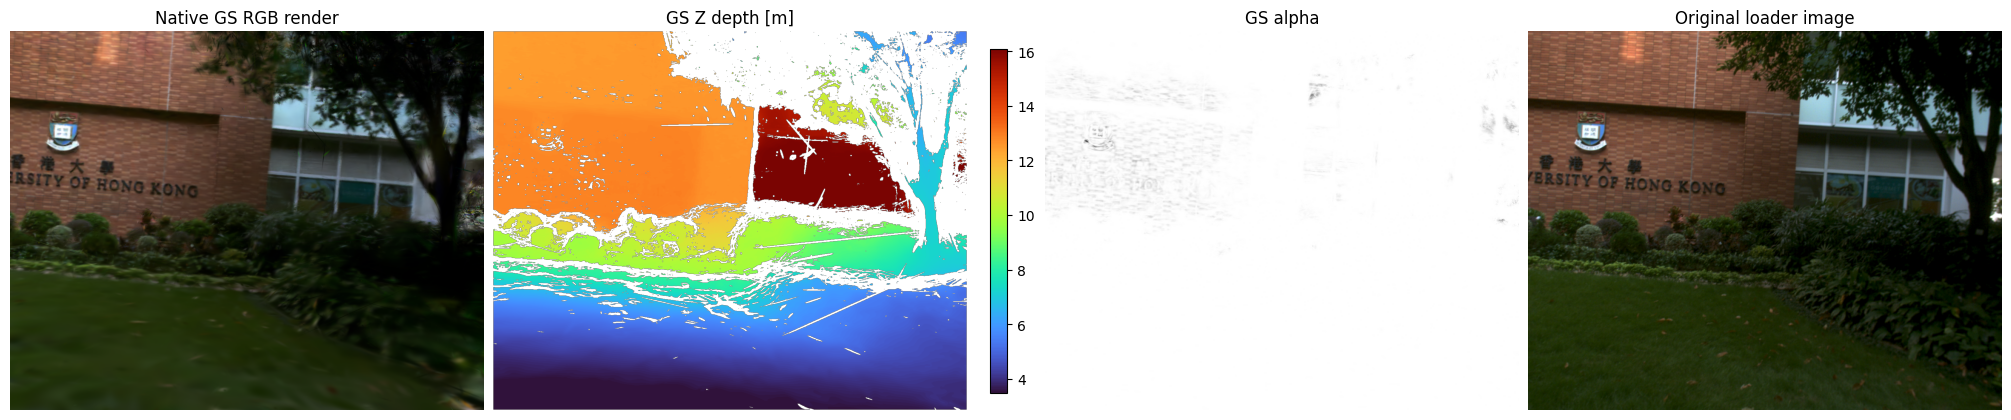

In [12]:
from dataclasses import replace
import matplotlib.pyplot as plt

qa_files = render_views(renderer, [QA_FRAME], CAMERA, RENDER_SCALE, EXPORT_ROOT)
qa = load_view(qa_files[0])
source_image = renderer.original_image(QA_FRAME, CAMERA)
mask = valid_depth_mask(qa, settings)
print('Rendered dimensions:', (qa['rgb'].shape[1], qa['rgb'].shape[0]))
print('Native render seconds:', float(qa['render_seconds']))
print('High-alpha, depth-filtered pixels:', int(mask.sum()))
if not mask.any():
    raise RuntimeError('No valid GS depth. Inspect alpha/depth thresholds before proceeding.')
depth = qa['depth'][mask]
print('Depth p05/median/p95 [m]:', np.percentile(depth, [5, 50, 95]))
print('Horizontal pixel footprint p05/median/p95 [mm]:',
      np.percentile(depth / qa['K'][0,0] * 1000, [5, 50, 95]))
print('Vertical pixel footprint p05/median/p95 [mm]:',
      np.percentile(depth / qa['K'][1,1] * 1000, [5, 50, 95]))

fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
axes[0].imshow(qa['rgb']); axes[0].set_title('Native GS RGB render')
depth_show = np.where(mask, qa['depth'], np.nan)
im = axes[1].imshow(depth_show, cmap='turbo',
                    vmin=np.percentile(depth, 5), vmax=np.percentile(depth, 95))
axes[1].set_title('GS Z depth [m]'); fig.colorbar(im, ax=axes[1], shrink=.7)
axes[2].imshow(qa['alpha'], vmin=0, vmax=1, cmap='gray'); axes[2].set_title('GS alpha')
if source_image is not None:
    axes[3].imshow(source_image); axes[3].set_title('Original loader image')
else:
    axes[3].text(.1, .5, 'Original image unavailable'); axes[3].set_title('Original image')
for ax in axes: ax.axis('off')
plt.show()


## 5. Single-view cloud and round-trip projection check

This export uses only frame 454, making it easy to see whether depth has warped a wall. It keeps exact GS pixel colors. Inspect from an oblique viewpoint as well as the source camera: matching the source image is guaranteed by back-projection and is not independent validation of depth.

The numerical round-trip verifies the coordinate convention:

\[
\pi_K\bigl(({}^W T_C)^{-1}\mathbf p_W\bigr)\simeq[u,v]^T.
\]

Depth discontinuity filtering may leave holes around thin objects. It removes samples instead of smoothing or moving them.


In [13]:
single_settings = replace(settings, min_other_views=0)
single_rows, single_stats = view_points(qa, [], single_settings)
single_dir = EXPORT_ROOT / ('single_' + digest(dict(view=str(qa_files[0]), settings=asdict(single_settings)))[:16])
single_dir.mkdir(parents=True, exist_ok=True)
single_npy = single_dir / 'single_view.npy'
single_ply = single_dir / 'single_view_gs_rgbd.ply'
atomic_npy(single_npy, single_rows)
write_ply_parts(single_ply, [single_npy], len(single_rows))
if not len(single_rows):
    raise RuntimeError('No single-view points survived filtering.')

sample_ids = np.linspace(0, len(single_rows)-1, min(10000, len(single_rows)), dtype=int)
sample = single_rows[sample_ids]
T_c_w = np.linalg.inv(qa['T_w_c'])
camera_points = xyz(sample) @ T_c_w[:3,:3].T + T_c_w[:3,3]
projected = camera_points @ qa['K'].T
uv = projected[:,:2] / projected[:,2,None]
expected = np.column_stack([sample['source_u'], sample['source_v']])
error = np.linalg.norm(uv-expected, axis=1)
print('Round-trip pixel error p50/p95/max:', np.percentile(error, [50,95,100]))
if np.max(error) > 0.1:
    raise RuntimeError('Coordinate round-trip error exceeds 0.1 pixel; inspect transform/precision before fusion.')
print('Single-view cloud:', single_ply)
print('Source pixel RGB is preserved; no multi-image averaging.')

if OPEN_SINGLE_VIEW:
    import open3d as o3d
    o3d.visualization.draw_geometries([o3d.io.read_point_cloud(str(single_ply))])


Round-trip pixel error p50/p95/max: [3.35172436e-05 1.18266541e-04 2.33693406e-04]
Single-view cloud: /home/ntd/data/fast_livo2/pings_results/gs_no_deskew/hku_landmark_stable_fastlivo2__2026-10-22_13-07-25/exports_gs_rgbd_v1/single_ba450d516d9fe417/single_view_gs_rgbd.ply
Source pixel RGB is preserved; no multi-image averaging.


## 6. Small multi-view preview

For a candidate point projected into another rendered camera, require

\[
|Z_j-D_j(u_j,v_j)|\le\tau_a+\tau_rD_j(u_j,v_j),
\]

with high alpha, no depth jump, and a camera-center baseline of at least `min_baseline_m`. By default, one other view must support it. These are consistency checks of the **same learned model**, not independent LiDAR measurements or ground truth. Nearby selected frames provide support; the notebook does not fit a time offset or move a point to achieve agreement.

For appearance, spatial patches are split into normal-direction bins. Select one frame per patch using summed \(\alpha\gamma^2/z^2\), where \(\gamma\) is the absolute view-incidence cosine. Samples from other frames in that patch are discarded, including displaced copies. Within each 1 mm voxel, keep one surviving source sample verbatim. No centroid or RGB blending is used. This reduces doubled text at the cost of possible holes and seams at patch boundaries.

Disk buckets bound fusion memory. RGB-D renders, filtered source samples, and finished buckets are cached atomically so an interrupted run can resume.


In [14]:
preview_ids = list(range(PREVIEW_BEGIN, min(PREVIEW_END, renderer.frame_count), PREVIEW_STEP))
print('Preview frames:', preview_ids)
preview_files = render_views(renderer, preview_ids, CAMERA, RENDER_SCALE, EXPORT_ROOT)
preview_result = export_rgbd_cloud(preview_files, settings, EXPORT_ROOT / 'preview')
print('Preview colored cloud:', preview_result['ply'])

if OPEN_PREVIEW:
    import open3d as o3d
    o3d.visualization.draw_geometries([o3d.io.read_point_cloud(preview_result['ply'])])


Preview frames: [440, 445, 450, 455, 460, 465, 470]


GS RGB-D views:   0%|          | 0/7 [00:00<?, ?view/s]

Filter GS depth consistency:   0%|          | 0/7 [00:00<?, ?view/s]

Accepted source samples: 4,909,876 | selecting coherent patch views


Fuse without averaging:   0%|          | 0/32 [00:00<?, ?bucket/s]

{
  "ply": "/home/ntd/data/fast_livo2/pings_results/gs_no_deskew/hku_landmark_stable_fastlivo2__2026-10-22_13-07-25/exports_gs_rgbd_v1/preview/cloud_88b7ce86d9000f0f/colored_gs_rgbd.ply",
  "source_samples": 4909876,
  "output_points": 1991051,
  "views": 7,
  "this_call_seconds": 6.836244371999783,
  "source": "native PINGS GS RGB and surf_depth",
  "sdf_used": false,
  "mesh_used": false,
  "positions_averaged": false,
  "rgb_averaged": false,
  "geometry": "retained back-projected GS depth samples; no model or pose optimization",
  "settings": {
    "alpha_min": 0.9,
    "min_depth_m": 0.5,
    "max_depth_m": 30.0,
    "pixel_stride": 1,
    "depth_edge_abs_m": 0.03,
    "depth_edge_rel": 0.005,
    "consistency_abs_m": 0.015,
    "consistency_rel": 0.003,
    "min_other_views": 1,
    "neighbor_views": 3,
    "min_baseline_m": 0.02,
    "min_incidence": 0.15,
    "output_voxel_m": 0.001,
    "color_patch_m": 0.25,
    "bucket_count": 32,
    "roi": null
  }
}
Preview colored cloud:

## 7. Full trajectory export

Enable `RUN_FULL_EXPORT` after inspecting the single-view geometry and preview cloud. No entire map is rasterized onto a 0.1 mm grid. Runtime scales with rendered pixels, selected views, filtering and disk I/O. The renderer timing printed above excludes caching and filtering; it is not a full-export ETA.

Full-scene rendering may need several GB of free disk space. Render/candidate caches are kept for resume. Use `roi` to focus on the text/wall area if a full scene is unnecessary; ROI affects exported points, not GPU render resolution.


In [15]:
if RUN_FULL_EXPORT:
    full_end = renderer.frame_count if FULL_END < 0 else min(FULL_END, renderer.frame_count)
    full_ids = list(range(FULL_BEGIN, full_end, FULL_STEP))
    print('Full export views:', len(full_ids))
    full_files = render_views(renderer, full_ids, CAMERA, RENDER_SCALE, EXPORT_ROOT)
    full_result = export_rgbd_cloud(full_files, settings, EXPORT_ROOT / 'full')
    print('Full colored cloud:', full_result['ply'])
else:
    print('Preview complete. Set RUN_FULL_EXPORT = True to export the full selected trajectory.')


Full export views: 304


GS RGB-D views:   0%|          | 0/304 [00:00<?, ?view/s]

Median native render time [s]: 0.047221726999850944


Filter GS depth consistency:   0%|          | 0/304 [00:00<?, ?view/s]

Accepted source samples: 248,523,702 | selecting coherent patch views


Fuse without averaging:   0%|          | 0/32 [00:00<?, ?bucket/s]

{
  "ply": "/home/ntd/data/fast_livo2/pings_results/gs_no_deskew/hku_landmark_stable_fastlivo2__2026-10-22_13-07-25/exports_gs_rgbd_v1/full/cloud_8c06e2347b17e38a/colored_gs_rgbd.ply",
  "source_samples": 248523702,
  "output_points": 20718000,
  "views": 304,
  "this_call_seconds": 579.0355627110002,
  "source": "native PINGS GS RGB and surf_depth",
  "sdf_used": false,
  "mesh_used": false,
  "positions_averaged": false,
  "rgb_averaged": false,
  "geometry": "retained back-projected GS depth samples; no model or pose optimization",
  "settings": {
    "alpha_min": 0.9,
    "min_depth_m": 0.5,
    "max_depth_m": 30.0,
    "pixel_stride": 1,
    "depth_edge_abs_m": 0.03,
    "depth_edge_rel": 0.005,
    "consistency_abs_m": 0.015,
    "consistency_rel": 0.003,
    "min_other_views": 1,
    "neighbor_views": 3,
    "min_baseline_m": 0.02,
    "min_incidence": 0.15,
    "output_voxel_m": 0.001,
    "color_patch_m": 0.25,
    "bucket_count": 32,
    "roi": null
  }
}
Full colored cloud: 

## Interpreting failures and detail limits

| Observation | Next check |
|---|---|
| GS RGB is sharp but single-view geometry bends | Inspect GS depth itself; do not blame mesh resolution or add synthetic points. |
| Single-view cloud looks good only from its source camera | The source projection is not a depth-accuracy test; inspect oblique views and multi-view support. |
| Preview has few points | Inspect alpha, baseline, frame step and depth-consistency rejection counts; do not disable all filters blindly. |
| Preview has doubled text | Check whether the seam lies on a patch boundary; inspect the depth disagreement rather than increasing voxel density. |
| Text is already blurred in the GS render | Denser output cannot recover missing training-image detail. |
| CUDA out of memory | Use `RENDER_SCALE=1`; the default scale 2 has four times as many pixels. |
| PLY is dense but fine geometry is absent | Sampling density is not geometric detail; review the reported pixel footprint and GS depth. |

The global model is rendered without SDF, coarse mesh sampling or anchor tangent patches. The new exporter is structurally different from the previous notebook; this does not guarantee that GS depth has the same quality as its RGB appearance on your dataset.
